# Session 5 — Finding Structure Without Labels

In Sessions 0 to 4 every example came with an answer: a species, a pass or fail, a diagnosis. Often the answers don't exist. You have the data and nobody has told you what is in it. **Unsupervised learning** looks for structure in data without being given a target.

This session covers the two main kinds: **clustering**, which groups similar points, and **dimensionality reduction**, which squeezes many features into a few so we can look at them. The main demonstration is k-means, the most common clustering method.

**By the end of the session you should be able to:**

1. describe how k-means places and refines its groups;
2. explain why the scale of each feature changes the clusters, and see it happen;
3. read a PCA plot and say what it keeps and what it throws away.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The outputs are already saved in the notebook. It runs in about fifteen seconds, and the numbers should match because every step uses a fixed seed.

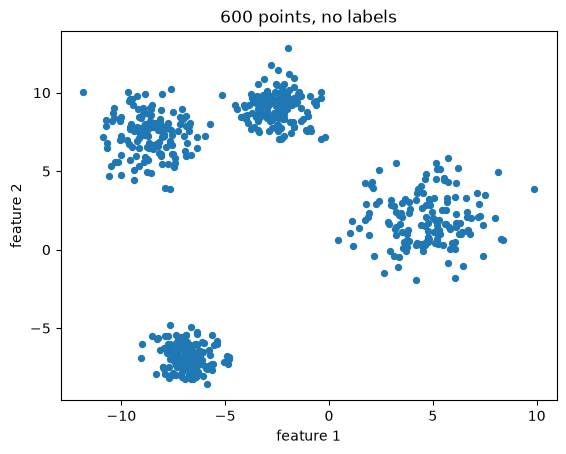

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
X, hidden = make_blobs(n_samples=600, centers=4, cluster_std=[1.0, 1.7, 0.8, 1.2], random_state=SEED)

plt.scatter(*X.T, s=18)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("600 points, no labels")
plt.show()

## 1. Points with no labels

We generate 600 points in two dimensions, drawn around four centres. The generator knows which centre produced each point, but we keep those labels out of the algorithm, so we can compare the result with them afterwards. Real data has no such answer sheet.

> **Pause:** how many groups can you see? Do the groups look the same size and shape?

There are four, with different spreads: the bottom-left group is tight and the right-hand one is much wider.

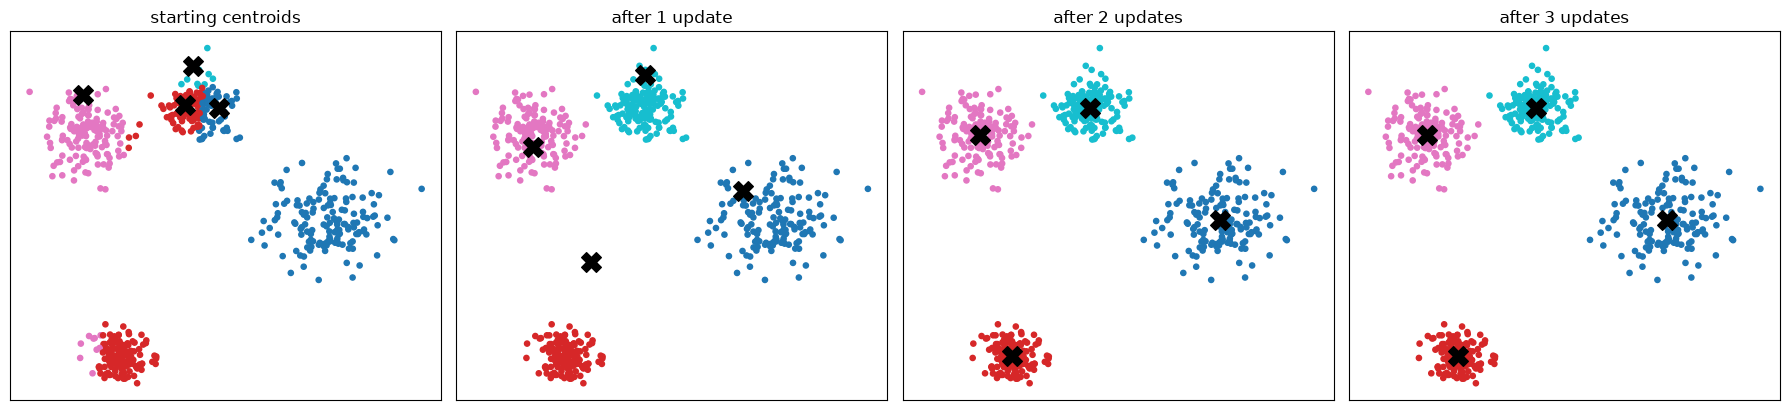

Updates until nothing changes: 3


In [2]:
rng = np.random.default_rng(1)
start = X[rng.choice(len(X), 4, replace=False)]  # four random points as the first centroids

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharex=True, sharey=True)
for ax, steps in zip(axes, [0, 1, 2, 3]):
    if steps == 0:
        centres, labels = start, np.linalg.norm(X[:, None] - start[None], axis=2).argmin(axis=1)
    else:
        km = KMeans(n_clusters=4, init=start, n_init=1, max_iter=steps, algorithm="lloyd").fit(X)
        centres, labels = km.cluster_centers_, km.labels_
    ax.scatter(*X.T, c=labels, s=14, cmap="tab10")
    ax.scatter(*centres.T, marker="X", s=200, c="k")
    ax.set(title="starting centroids" if steps == 0 else f"after {steps} update{'s' if steps > 1 else ''}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()
print("Updates until nothing changes:", KMeans(n_clusters=4, init=start, n_init=1, algorithm="lloyd").fit(X).n_iter_)

## 2. k-means: place centres, then refine them

k-means is told how many groups to find, here **K = 4**, and then repeats two steps:

1. give every point to its nearest centre;
2. move each centre to the average position of the points it was given.

The figure shows this with four starting centres picked from random data points. This is a bad start on purpose: three of the four centres sit in or next to the top-middle group, the fourth is in the top-left group, and none is near the bottom-left or right-hand group. After one update, one centre has been pulled into the right-hand group and another is stranded in the empty space below the top groups. After two updates every group has its own centre, and the printed line shows that k-means stopped after 3 rounds, when a round no longer changed anything.

This loop is old: Stuart Lloyd described it at Bell Labs in 1957 (it was published in 1982, and `algorithm="lloyd"` in the code is named after him), and James MacQueen gave it the name k-means in 1967.

k-means always stops quickly, but where it stops depends on the starting centres. A poor start can leave two centres in one group and none in another, so scikit-learn's `KMeans` can try several starts (`n_init`) and keep the best. We use 20.

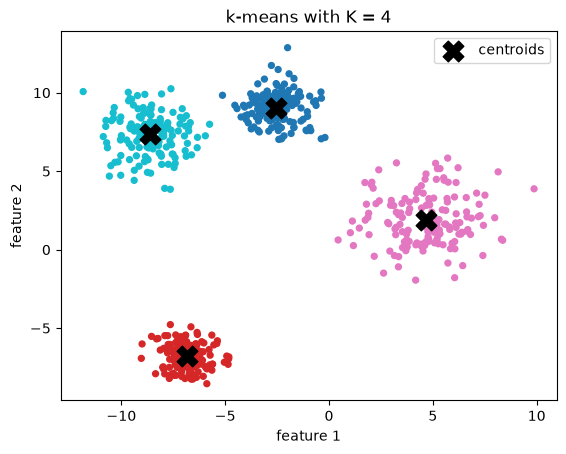

Silhouette score: 0.757
Agreement with the hidden labels (adjusted Rand index): 0.996
Cluster sizes: [149 150 150 151]  true sizes: [150 150 150 150]


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_scaled)
centres = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(*X.T, c=kmeans.labels_, s=18, cmap="tab10")
plt.scatter(*centres.T, marker="X", s=220, c="k", label="centroids")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("k-means with K = 4")
plt.legend()
plt.show()
print(f"Silhouette score: {silhouette_score(X_scaled, kmeans.labels_):.3f}")
print(f"Agreement with the hidden labels (adjusted Rand index): {adjusted_rand_score(hidden, kmeans.labels_):.3f}")
print("Cluster sizes:", np.bincount(kmeans.labels_), " true sizes:", np.bincount(hidden))

## 3. The result

With the features standardised, k-means with K = 4 finds the four groups. The cluster sizes are 149, 150, 150 and 151, against the true 150 each. The **adjusted Rand index**, which measures agreement with the hidden labels (1.0 is perfect), is 0.996. The **silhouette score**, 0.757, doesn't need labels at all: for each point it compares the distance to its own group with the distance to the nearest other group, and runs from −1 to 1, with higher meaning tighter, better-separated groups.

The numbers 0 to 3 that name the clusters have no order or meaning. Swapping them would change nothing.

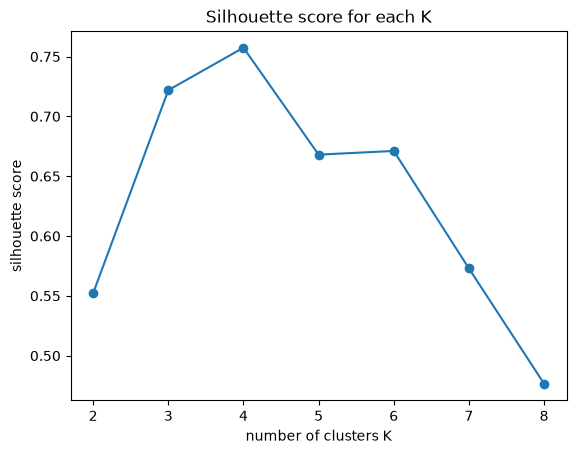

{2: 0.552, 3: 0.722, 4: 0.757, 5: 0.668, 6: 0.671, 7: 0.573, 8: 0.477}


In [4]:
scores = {k: silhouette_score(X_scaled, KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_scaled)) for k in range(2, 9)}
plt.plot(list(scores), list(scores.values()), marker="o")
plt.xlabel("number of clusters K")
plt.ylabel("silhouette score")
plt.title("Silhouette score for each K")
plt.show()
print({k: round(v, 3) for k, v in scores.items()})

## 4. How many clusters?

In practice we don't know K. One clue is to try several values and compare silhouette scores. The score is highest at K = 4 (0.757). K = 3 is next (0.722), then K = 6 (0.671) and K = 5 (0.668), with K = 8 the lowest at 0.477.

So the silhouette agrees with the four groups we generated. It is a measure of geometry only: it says four compact groups fit this representation of the points best. On real data the peak is usually less sharp, and the score can't tell you whether the groups mean anything.

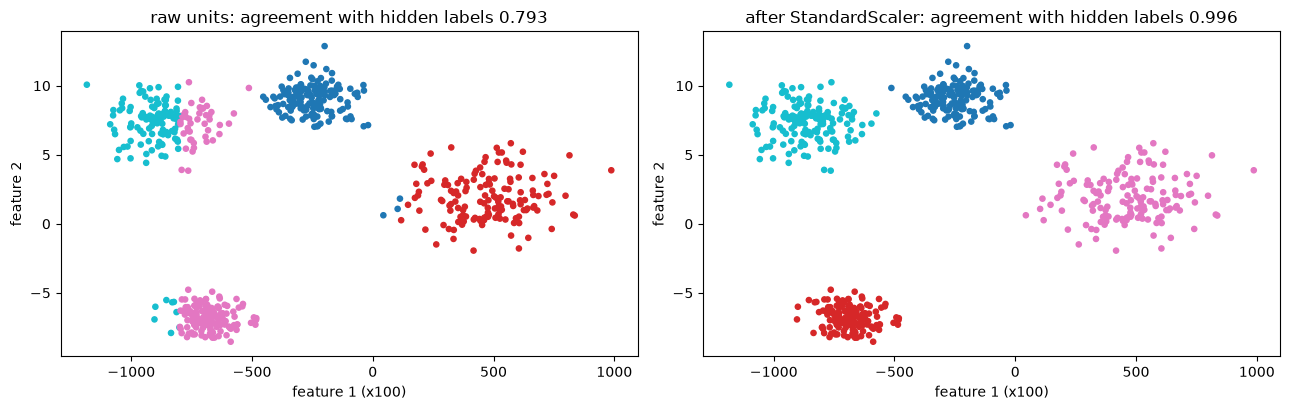

In [5]:
X_stretched = X.copy()
X_stretched[:, 0] *= 100  # feature 1 now has a spread about a hundred times larger

labels_raw = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(X_stretched)
labels_scaled = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(StandardScaler().fit_transform(X_stretched))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, labels, title in zip(axes, [labels_raw, labels_scaled], ["raw units", "after StandardScaler"]):
    ax.scatter(X_stretched[:, 0], X_stretched[:, 1], c=labels, s=14, cmap="tab10")
    ax.set(title=f"{title}: agreement with hidden labels {adjusted_rand_score(hidden, labels):.3f}", xlabel="feature 1 (x100)", ylabel="feature 2")
plt.tight_layout()
plt.show()

## 5. What does "close" mean? The effect of scale

k-means uses distances, so each feature's units matter. Below, we multiply feature 1 by 100, as if one column were in centimetres and another in metres, and run the same algorithm twice: once on the raw numbers, and once after `StandardScaler`.

> **Pause:** nothing about the points' arrangement has changed, only the units. Will the clusters change?

On raw numbers the agreement with the hidden labels drops from 0.996 to 0.793. Feature 1 now spans about 2,000 units and feature 2 about 20, so the distances are decided almost entirely by feature 1. The two groups on the left, which differ mainly in feature 2, are partly merged, and the algorithm splits the wide group differently. After standardising, the clustering is as good as before: 0.996.

The model can't know what the numbers mean. Choosing the units, or the scaling, decides what "close" means, so it is part of the model.

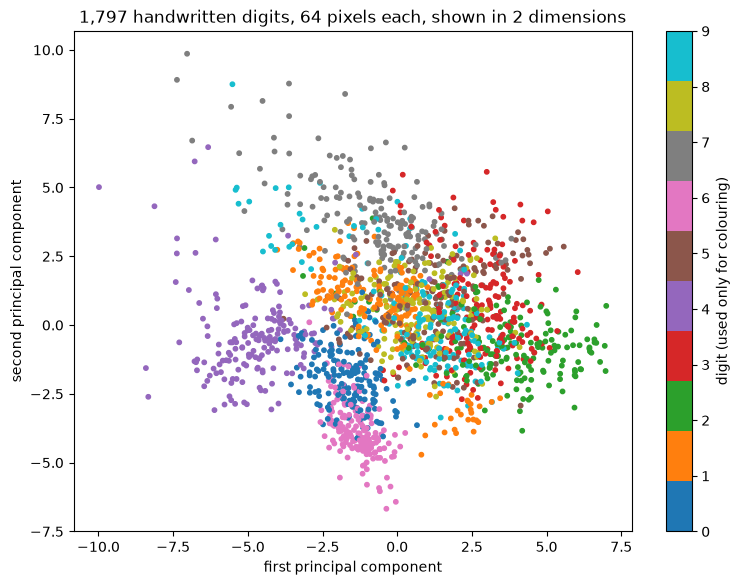

Variance kept by the first two components: 0.216
Components needed to keep 90% of the variance: 31 of 64


In [6]:
digits = load_digits()
X_digits = StandardScaler().fit_transform(digits.data)
pca = PCA(n_components=2).fit(X_digits)
X_2d = pca.transform(X_digits)

plt.figure(figsize=(9, 6.5))
points = plt.scatter(*X_2d.T, c=digits.target, s=10, cmap="tab10")
plt.colorbar(points, label="digit (used only for colouring)")
plt.xlabel("first principal component")
plt.ylabel("second principal component")
plt.title("1,797 handwritten digits, 64 pixels each, shown in 2 dimensions")
plt.show()
print(f"Variance kept by the first two components: {pca.explained_variance_ratio_.sum():.3f}")
full = PCA().fit(X_digits)
print(f"Components needed to keep 90% of the variance: {int(np.searchsorted(np.cumsum(full.explained_variance_ratio_), 0.90) + 1)} of 64")

## 6. Dimensionality reduction: a map of 64 features

The digits dataset has 1,797 handwritten digits, each an 8×8 image, so 64 features per digit. We can't draw 64 dimensions. **Principal component analysis (PCA)** finds the directions along which the data varies the most, and keeps the first few. Plotting the first two gives a flat map of the whole dataset, in the same way that a street map drops height and keeps layout.

The colours show the true digit, but PCA never saw them. Some digits sit apart: 4 (purple) on the left, 2 (green) on the right, and 0 (blue) and 6 (pink) at the bottom each have a region of their own. Others overlap heavily around the centre, where 1, 3, 5, 8 and 9 mix together.

The first two components keep 21.6% of the variance. The remaining 78% is lost, which explains the overlap. To keep 90% of the variance takes 31 of the 64 components, so these digits have no simple low-dimensional form. A tangle in the 2D map doesn't prove that the digits can't be told apart in 64 dimensions, and a supervised model can classify these digits well.

In [7]:
digit_clusters = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit_predict(X_digits)
print(f"Agreement of 10 k-means clusters with the true digits: {adjusted_rand_score(digits.target, digit_clusters):.3f}")
print(pd.crosstab(digit_clusters, digits.target, rownames=["cluster"], colnames=["digit"]))

Agreement of 10 k-means clusters with the true digits: 0.478
digit      0   1   2    3    4   5    6    7    8    9
cluster                                               
0          0   0  88   10    1  69    0    8   11    1
1        177   0   0    0    0   0    1    0    0    0
2          0   1   0    0    0   4  174    0    2    0
3          1   0   0    0  158   2    0    0    0    0
4          0   0   8  157    0  77    0    0   46  146
5          0  96  28    8    2  22    5    0  100    3
6          0  58   4    0    7   3    1    3   13   19
7          0  27  48    1    0   0    0    0    0    0
8          0   0   0    0    9   0    0   18    0    3
9          0   0   1    7    4   5    0  150    2    8


Clustering the same data into 10 groups shows the same pattern in a different form. The adjusted Rand index against the true digits is only 0.478. Some clusters are almost pure: cluster 1 holds 177 of the 178 zeros, cluster 2 holds 174 of the sixes and cluster 3 holds 158 of the fours. Others mix several digits. Cluster 4 contains 157 threes, 146 nines, 77 fives and 46 eights, and cluster 5 mixes 96 ones with 100 eights.

The clusters group digits that *look alike in pixel space*, which is not the same as being the same digit. That is the central limit of unsupervised methods: they find structure, and whether it matches the categories you care about has to be checked against something else.

## Practical takeaways

- Scale the features before clustering, unless the raw units are what you want to compare.
- Run k-means with several starts (`n_init`) and a fixed seed.
- Use silhouette scores as one clue for K, and plot the clusters as well.
- Use PCA to look at high-dimensional data, and report how much variance the map keeps.
- Cluster numbers and PCA axes have no built-in meaning. Give a group a name only after you have looked at what is in it.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## What k-means minimises

With $K$ centres $\mu_1,\dots,\mu_K$ and $c_i$ the centre assigned to point $x_i$, k-means looks for the arrangement with the smallest within-cluster sum of squares

$$
J=\sum_{i=1}^{n}\lVert x_i-\mu_{c_i}\rVert^2 .
$$

Each of the two steps (assign, then move) can only lower $J$ or leave it unchanged, so the process always stops. It finds a local minimum, not necessarily the best one, which is why several starts help. Because the objective uses squared distance to a centre, k-means prefers compact, round groups of similar size. It struggles with curved shapes, very different densities and outliers.

## The silhouette score

For a point $i$, let $a(i)$ be its average distance to the other points in its cluster and $b(i)$ the smallest average distance to the points of any other cluster:

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}} .
$$

Values near 1 mean the point sits well inside its cluster, values near 0 mean it is on a boundary, and negative values suggest it may be in the wrong cluster. The score reported above is the average over all points.

## PCA

For centred data $X$, the first principal direction is the unit vector $w_1$ along which the projected data has the largest variance:

$$
w_1=\arg\max_{\lVert w\rVert=1}\operatorname{Var}(Xw).
$$

The second direction does the same under the extra condition that it is perpendicular to the first, and so on. The variance each component keeps is available as `explained_variance_ratio_`.

## Where this leads

Learned representations such as embeddings (Session 10) place similar items near each other without labels, and modern language models are first trained on unlabelled text. In each case the question is the one from this session: which representation makes the useful structure visible?